## Case study on heat transfer in Li-ion batteries

https://doi.org/10.1016/j.jpowsour.2013.11.107  

1. (15 min) Re-read the paper and summarize its general approach and major findings
2. (30 min) What is the general equation? a) Start from the general equation derived in the course (without any assumptions made) and show how the paper's equation is obtained. b) What assumptions are made in their equation? c) What are the boundary conditions? d) What are some practical considerations that may lead to measurements deviating from simulations (for instance, is thermal conductivity in the battery constant? is there a spatial dependence? are the boundary conditions appropriate, and when might they deviate from the assumed?)

Collaborate on the following slides: https://docs.google.com/presentation/d/1btceqiNeWZrMnEXMliJLCU_2QiVu3Y8lK71NjIk96wc/edit?usp=sharing 

3. (20 min) Simulate the transient radial temperature profile from Equation 1, using Python. Use thermophysical properties described in paper. 

4. (20 min) Simulate the transient axial temperature profile from Equation 1, using Python. Use thermophysical properties described in paper. 

5. (15 min) Compare to results shown in paper. What are some practical design considerations to improve conductive heat transfer in cylindrical lithium ion batteries and avoid excessive heating?

6. (25 min) Write up above into a document including generated figures and submit as addendum to the Problem Set.


/var/folders/_5/fh5gx3516nn4153v404bdwhh0000gn/T/ipykernel_54693/2574982915.py:60: DeprecationWarning: Calling np.sum(generator) is deprecated, and in the future will give a different result. Use np.sum(np.fromiter(generator)) or the python sum builtin instead.
  theta_soln = q_flux / (rho * cp * L) * t + np.sum((-1)**(n+1)*2*q_flux*L/(k*(n*np.pi)**2) * np.cos(n*np.pi*z/L) * np.exp(-k*(n*np.pi)**2/(rho*cp*L**2) * t) for n in range(1,300))


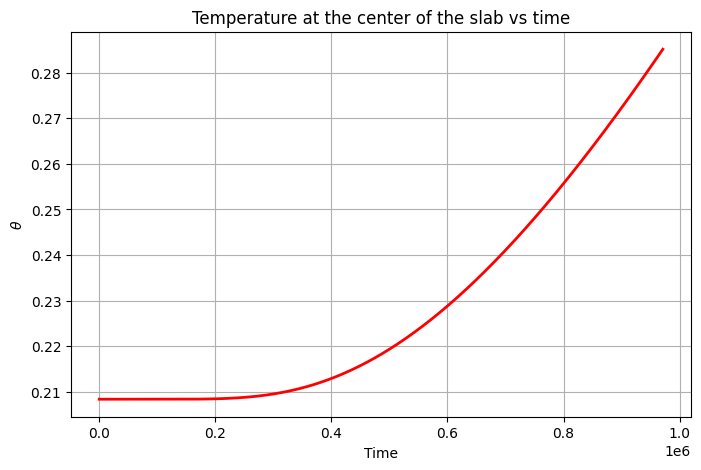

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# parameters
rho = 2285.0            # replace with actual density if known
cp = 1700.0
k = 0.2
alpha = k / (rho * cp)   # thermal diffusivity

L = 1.0              # length of slab
Nz = 201             # number of spatial nodes
dz = L / (Nz - 1)
z = np.linspace(0, L, Nz)

# heat flux at z = H, use measured value when available
q_flux = 1.0

# time stepping
dt = 0.25 * dz**2 / alpha   # stable explicit scheme
Nt = 8000
t = np.linspace(0, Nt * dt, Nt + 1)

# initial condition
theta = np.zeros(Nz)

# boundary conditions:
# d(theta)/dz = 0 at z = 0
# d(theta)/dz = q'' / k at z = H

def apply_boundary_conditions(u):
    # zero gradient at z = 0
    u[0] = u[1]

    # specified heat flux at z = H: dtheta/dz = q'' / k
    u[-1] = u[-2] + dz * q_flux / k
    return u

# finite-difference update for the 1D diffusion equation
# d theta / dt = alpha * d^2 theta / dz^2
def fdm(u):
    u_hist = np.zeros((Nt + 1, len(u)))
    u_hist[0] = u

    for n in range(0, Nt):
        u = apply_boundary_conditions(u.copy())
        u[1:-1] = u[1:-1] + (alpha * dt / dz**2) * (
            u[:-2] - 2*u[1:-1] + u[2:]
        )
        u = apply_boundary_conditions(u)
        u_hist[n + 1] = u

    return u_hist

# enforce initial BCs and solve
theta = apply_boundary_conditions(theta)
theta_history = fdm(theta)
theta_center = theta_history[:, Nz // 2]

z = 0.5
theta_soln = q_flux / (rho * cp * L) * t + q_flux / (rho * cp) * (z**2 - L**2 / 3) + np.sum((-1)**(n+1)*2*q_flux*L/(k*(n*np.pi)**2) * np.cos(n*np.pi*z/L) * np.exp(-k*(n*np.pi)**2/(rho*cp*L**2) * t) for n in range(1,300)) 

# plot theta vs time at the center
plt.figure(figsize=(8, 5))
plt.plot(t, theta_center, "b-", linewidth=2)
plt.plot(t, theta_soln, "r-", linewidth=2)
plt.xlabel("Time")
plt.ylabel(r"$\theta$")
plt.title("Temperature at the center of the slab vs time")
plt.grid(True)
plt.show()